# Required SNR versus chromatic dispersion

Fig. 3 of the OFC 2027 paper *End-to-End Optimization of Direct-Detection Optical Systems*: SNR (Es/N0)
required for BER 1e-3 versus the chromatic dispersion index γ = −2β₂R_b²L of Secondini et al. (JLT 2020),
R_b being the bit rate, for the methods and configurations of `ofc_e2e.ipynb`: linear FFE, RX-only NN,
E2E-NN and E2E-LUT-DT, in the thermal-noise regime with PAM-4 and in the ASE-noise regime with BPAM-4,
with TX filter bandwidths 0.5 and 0.25 R_s.

The fiber length sets γ (0.69 at 10 km and 40 Gbps). Every length is a separate configuration, with its
own digital surrogate and training, cached in `results/ofc_e2e/` like the configurations of
`ofc_e2e.ipynb`; the 10-km configurations are those of Fig. 2 and are shared with that notebook,
decision trees included. The knobs are those of `ofc_e2e.ipynb`, except the list of fiber lengths;
`INITIALIZATION` selects the E2E start as there.

## 1. Setup and knobs

In [1]:
# Resolve paths independently of the notebook's working directory.
from pathlib import Path
import os
import sys
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "functions" / "link.py").is_file())
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

%load_ext autoreload
%autoreload 2

from dataclasses import replace
import math
import shutil
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import Markdown, display

from functions.decision_tree import complexity, decision_trees
from functions.evaluation import threshold
from functions.parameters import Budget, Case, LinkParameters, EVALUATION_LEVEL_DB
from functions.pipeline import case_folder, run_case, training_folder

%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# ---------------- knobs (as in ofc_e2e.ipynb, except the fiber lengths) ----------------
INITIALIZATION   = "zero-mean"                 # E2E start: "warmstart", the paper's (RX NN trained with the
                                               # conventional TX, TX NN fitted to the conventional voltages, then
                                               # joint training), or "zero-mean" (TX NN and RX NN from random
                                               # weights; TX NN output with zero mean, functions.dsp.ZeroMeanTransmitter)
REGIMES          = ["electrical", "optical"]   # noise: "electrical" (thermal) and/or "optical" (ASE)
FORMAT           = {"electrical": "pam4", "optical": "bpam"}
TX_BANDWIDTH_GHZ = [10, 5]                     # TX filter 3-dB bandwidth: 0.5 and 0.25 Rs at 20 GBd
TX_PULSE         = "nrz"                       # "nrz" or "rrc"
TX_FILTER        = "gaussian"                  # H_TX, analog after the DAC: "gaussian", "rectangular" or "none"
OPTICAL_FILTER   = {"electrical": "none", "optical": "supergaussian"}   # H_opt per noise regime
OPTICAL_FILTER_GHZ = 30                        # full 3-dB width of the super-Gaussian H_opt: 1.5 Rs at 20 GBd
SUPERGAUSSIAN_ORDER = 4
RX_FILTER        = "gaussian"                  # H_RX: "gaussian" or "none"
RX_FILTER_GHZ    = 10
RX_FILTER_BEFORE_ADC = True                    # True: analog H_RX before the ADC, refitted by the digital surrogate
DAC_BITS         = 6                           # None: ideal converter
ADC_BITS         = 6
FIBER_KM         = [0., 5., 10., 15., 20., 25., 29.1824]   # fiber lengths: gamma from 0 to 2.03 at 40 Gbps
FIG2_KM          = 10.                         # the fiber length of Fig. 2: its configurations (labels without the
                                               # length) and decision trees are shared with ofc_e2e.ipynb
BETA2_PS2_PER_KM = -21.7                       # C-band standard single-mode fiber
MZM_BIAS         = "null"
ANALOG_SPS       = 2                           # samples per symbol of the analog simulation
RX_SPS           = {"electrical": 1, "optical": 2}   # ADC and RX DSP samples per symbol
POWER_REFERENCE  = "mean"                      # Secondini's: every TX at unit mean optical power
PRECODE          = True                        # differential precoding of the BPAM sign bit
TRAINING_LEVEL_DB = {"electrical": 18.92, "optical": 16.05}   # SNR or OSNR during training
METHODS          = ["linear", "rx_only", "e2e"]
SURROGATE_STEPS  = 40_000                      # digital-surrogate fit
RX_STEPS         = 100_000                     # RX initialization with the conventional TX
TX_STEPS         = 8_000                       # TX NN fitted to the conventional voltages
E2E_STEPS        = 300_000                     # TX NN and RX NN trained jointly
RX_ONLY_STEPS    = 300_000                     # RX-only reference, continued from the RX initialization
EVAL_BLOCKS      = 128                         # held-out blocks of 32768 symbols per level, at least
SEED             = {"warmstart": 0, "zero-mean": 3}   # seed of each E2E start
LABEL            = {"electrical": "htx_surrogate{length}_mean_rx1sps_300k", "optical": "htx_surrogate{length}_300k"}
                                               # {length}: "" at FIG2_KM, "_<km>km" otherwise; part of the cache key
FORCE_RETRAIN    = False                       # True: delete and recompute every configuration, those of Fig. 2 too
TREE_LEAVES      = 1024                        # RX decision trees: leaves per tree (2047 nodes); None: no trees
TREE_STRUCTURE   = None                        # "symbol", "bit" or None, as the RX NNs
TREE_SOURCE      = "surrogate"                 # training windows of the trees: "surrogate" or "simulator"
SNR_RANGE_DB     = (13, 22)                    # SNR axis of Fig. 2: test levels of the trees at FIG2_KM
REQUIRED_SNR_DB  = (15, 26)                    # y axis of the figure

WORK = PROJECT_ROOT / "results" / "ofc_e2e"
BUDGET = Budget(surrogate_steps=SURROGATE_STEPS, rx_steps=RX_STEPS, tx_steps=TX_STEPS, joint_steps=E2E_STEPS,
                rx_only_steps=RX_ONLY_STEPS, eval_blocks=EVAL_BLOCKS)
LINKS = {regime: LinkParameters(tx_pulse=TX_PULSE, tx_filter=TX_FILTER, optical_filter=OPTICAL_FILTER[regime],
                                optical_gaussian_bandwidth=OPTICAL_FILTER_GHZ * 1e9,
                                optical_supergaussian_order=SUPERGAUSSIAN_ORDER, rx_filter=RX_FILTER,
                                rx_filter_bandwidth=RX_FILTER_GHZ * 1e9, rx_filter_before_adc=RX_FILTER_BEFORE_ADC,
                                dac_bits=DAC_BITS, adc_bits=ADC_BITS, fiber_length_km=FIG2_KM,
                                beta2_ps2_per_km=BETA2_PS2_PER_KM, analog_sps=ANALOG_SPS,
                                power_reference=POWER_REFERENCE, mzm_bias=MZM_BIAS,
                                rx_sps=None if RX_SPS[regime] == 2 else RX_SPS[regime])   # None: as the DSP
         for regime in ("electrical", "optical")}
RS_GHZ = LINKS["optical"].symbol_rate / 1e9    # symbol rate in GBd, for the normalized bandwidths
# ASE: Es/N0 = OSNR + 10 log10(2 B_ref / R_s), with B_ref = 12.5 GHz and two polarizations (0.97 dB at 20 GBd)
SHIFT = {"electrical": 0., "optical": 10 * np.log10(2 * LINKS["optical"].osnr_reference_bandwidth
                                                    / LINKS["optical"].symbol_rate)}


def gamma(km):
    """Chromatic dispersion index -2 beta2 Rb^2 L of Secondini et al. (JLT 2020), Rb the bit rate."""
    p = LINKS["optical"]
    return -2 * p.beta2_ps2_per_km * 1e-27 * (p.bits_per_symbol * p.symbol_rate) ** 2 * km * 1e3


START = {"warmstart": "conventional", "zero-mean": "zero-mean"}   # Case.initialization of each E2E start


def reference_case(case):
    """The warm-start configuration of a case: its linear FFE and RX-only NN serve every E2E start."""
    return replace(case, initialization=START["warmstart"], seed=SEED["warmstart"])


def make_case(regime, tx_bandwidth_ghz, km, initialization=INITIALIZATION):
    length = "" if km == FIG2_KM else f"_{km:g}km"
    return Case(regime=regime, fmt=FORMAT[regime], tx_bandwidth_ghz=float(tx_bandwidth_ghz), precode=PRECODE,
                training_level_db=TRAINING_LEVEL_DB[regime], link=replace(LINKS[regime], fiber_length_km=float(km)),
                seed=SEED[initialization], label=LABEL[regime].format(length=length),
                initialization=START[initialization])


CASES = [make_case(r, b, km) for r in REGIMES for b in TX_BANDWIDTH_GHZ for km in FIBER_KM]
print(f"E2E start: {INITIALIZATION}, seed {SEED[INITIALIZATION]}")
print(f"{len(CASES)} configurations; results in {WORK}")
for km in FIBER_KM:   # gamma scales with beta2 Rb^2 L: the same gamma at 100 Gbps over (40/100)^2 times the length
    print(f"  {km:8g} km: gamma = {gamma(km):.2f}; at 100 Gbps, {km * .16:5.2f} km in the C-band or "
          f"{km * .16 * abs(BETA2_PS2_PER_KM):5.1f} km in the O-band (beta2 = -1 ps^2/km)")

device: cuda
E2E start: zero-mean, seed 3
28 configurations; results in c:\Users\celli\Documents\MLforCPO2\results\ofc_e2e
         0 km: gamma = 0.00; at 100 Gbps,  0.00 km in the C-band or   0.0 km in the O-band (beta2 = -1 ps^2/km)
         5 km: gamma = 0.35; at 100 Gbps,  0.80 km in the C-band or  17.4 km in the O-band (beta2 = -1 ps^2/km)
        10 km: gamma = 0.69; at 100 Gbps,  1.60 km in the C-band or  34.7 km in the O-band (beta2 = -1 ps^2/km)
        15 km: gamma = 1.04; at 100 Gbps,  2.40 km in the C-band or  52.1 km in the O-band (beta2 = -1 ps^2/km)
        20 km: gamma = 1.39; at 100 Gbps,  3.20 km in the C-band or  69.4 km in the O-band (beta2 = -1 ps^2/km)
        25 km: gamma = 1.74; at 100 Gbps,  4.00 km in the C-band or  86.8 km in the O-band (beta2 = -1 ps^2/km)
   29.1824 km: gamma = 2.03; at 100 Gbps,  4.67 km in the C-band or 101.3 km in the O-band (beta2 = -1 ps^2/km)


## 2. Training and evaluation

Every fiber length is a configuration of `ofc_e2e.ipynb`: its own digital surrogate (the dispersion
belongs to the analog link), RX initialization, TX pretraining, joint and RX-only training, linear FFE
fitted at every level, held-out BER on the reference simulator over the standard grid of the regime.
Computed configurations are loaded; a new one takes as long as one of `ofc_e2e.ipynb`. With
`INITIALIZATION = "zero-mean"` the E2E starts from random weights, as described in `ofc_e2e.ipynb`,
and the linear FFE and RX-only NN are those of the warm start.

In [2]:
summaries = {}
for case in CASES:
    if FORCE_RETRAIN:
        for folder in (case_folder(WORK, case, BUDGET, EVALUATION_LEVEL_DB[case.regime]), training_folder(WORK, case, BUDGET)):
            shutil.rmtree(folder, ignore_errors=True)
    reference = reference_case(case)                 # the case itself with the warm start
    summaries[case.name] = run_case(reference, WORK, BUDGET, methods=METHODS, device=device)
    if case != reference:                            # "zero-mean": its E2E-NN, the references of the warm start
        e2e = run_case(case, WORK, BUDGET, methods=["e2e"], device=device)
        summaries[case.name]["results"]["e2e"] = e2e["results"]["e2e"]
        summaries[case.name]["eyes"]["e2e"] = e2e["eyes"]["e2e"]


########## electrical_pam4_bw10_htx_surrogate_0km_mean_rx1sps_300k: thermal noise, PAM4, TX filter bandwidth 10 GHz, htx_surrogate_0km_mean_rx1sps_300k ##########
=== Digital surrogate: fit of the analog link ===  (already fitted)
=== E2E: zero-mean TX NN and RX NN trained jointly from random weights - BCE ===
  step  25000  loss 0.00009303
  step  50000  loss 0.00025325
  step  75000  loss 0.00020781
  step 100000  loss 0.00037719
  step 125000  loss 0.00041968
  step 150000  loss 0.00004312
  step 175000  loss 0.00036338
  step 200000  loss 0.00008015
  step 225000  loss 0.00012364
  step 250000  loss 0.00036262
  step 275000  loss 0.00021803
  step 300000  loss 0.00046606
=== BER on the simulator: E2E ===
SNR   14.0 dB   BER 1.030e-02
SNR   15.0 dB   BER 5.153e-03
SNR   16.0 dB   BER 2.275e-03
SNR   17.0 dB   BER 8.617e-04
SNR   17.5 dB   BER 4.729e-04
SNR   18.0 dB   BER 2.611e-04
SNR   18.5 dB   BER 1.272e-04
SNR   19.0 dB   BER 6.140e-05
SNR   19.5 dB   BER 2.944e-05
SNR   20.0 

## 3. RX decision trees

As in `ofc_e2e.ipynb`: one four-class tree per symbol for PAM-4, one tree per bit for BPAM, 1024 leaves,
trained on windows at five levels around the level where the E2E RX NN reaches BER 1e-3 (generated
through the digital surrogate with `TREE_SOURCE = "surrogate"`), tested on the reference simulator.
Test levels: at `FIG2_KM` those of Fig. 2, the integer levels of `SNR_RANGE_DB`, so that the trees are
shared with `ofc_e2e.ipynb`; at the other lengths the integer levels from 2 dB below to 7 dB above the
E2E RX NN level at BER 1e-3, which follow the curves as they move with the dispersion. A configuration
whose E2E RX NN does not reach BER 1e-3 gets no trees.

In [3]:
def tree_levels(case):
    """Test levels of the trees, in the levels of the regime (SNR for thermal noise, OSNR for ASE)."""
    if case.link.fiber_length_km == FIG2_KM:    # as ofc_e2e.ipynb: the integer levels of the Fig. 2 axis
        low, high = SNR_RANGE_DB[0] - SHIFT[case.regime] - .2, SNR_RANGE_DB[1] - SHIFT[case.regime] + .2
        return [float(l) for l in range(math.ceil(low), math.floor(high) + 1)]
    nn = threshold(summaries[case.name]["results"]["e2e"]["points"]["reference"])["level_db"]
    return [float(l) for l in range(math.floor(nn) - 2, math.ceil(nn) + 8)]


trees = {}
if TREE_LEAVES:
    rows = ["| Configuration | γ | Nodes | Average depth | Comparisons per bit | Memory per bit |",
            "|---|---:|---:|---:|---:|---:|"]
    for case in CASES:
        if threshold(summaries[case.name]["results"]["e2e"]["points"]["reference"]) is None:
            print(f"{case.name}: the E2E RX NN does not reach BER 1e-3, no trees")
            continue
        t = trees[case.name] = decision_trees(case, WORK, BUDGET, tree_levels(case), TREE_STRUCTURE, TREE_LEAVES,
                                              source=TREE_SOURCE, device=device, verbose=False)
        c = complexity(t)
        rows.append(f"| {case.name} | {gamma(case.link.fiber_length_km):.2f} | {'/'.join(map(str, c['nodes']))} | "
                    f"{'/'.join(f'{d:.1f}' for d in c['average_depth'])} | {c['comparisons_per_bit']:.1f} | "
                    f"{c['memory_kbit_per_bit']:.1f} kbit |")
    display(Markdown("\n".join(rows) + "\n\nPer-tree values separated by /; average depth at the test level closest "
                     "to BER 1e-3."))

| Configuration | γ | Nodes | Average depth | Comparisons per bit | Memory per bit |
|---|---:|---:|---:|---:|---:|
| electrical_pam4_bw10_htx_surrogate_0km_mean_rx1sps_300k | 0.00 | 2047 | 8.2 | 4.1 | 6.1 kbit |
| electrical_pam4_bw10_htx_surrogate_5km_mean_rx1sps_300k | 0.35 | 2047 | 8.2 | 4.1 | 6.1 kbit |
| electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k | 0.69 | 2047 | 8.5 | 4.2 | 6.1 kbit |
| electrical_pam4_bw10_htx_surrogate_15km_mean_rx1sps_300k | 1.04 | 2047 | 8.5 | 4.3 | 6.1 kbit |
| electrical_pam4_bw10_htx_surrogate_20km_mean_rx1sps_300k | 1.39 | 2047 | 8.2 | 4.1 | 6.1 kbit |
| electrical_pam4_bw10_htx_surrogate_25km_mean_rx1sps_300k | 1.74 | 2047 | 8.7 | 4.4 | 6.1 kbit |
| electrical_pam4_bw10_htx_surrogate_29.1824km_mean_rx1sps_300k | 2.03 | 2047 | 8.6 | 4.3 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_0km_mean_rx1sps_300k | 0.00 | 2047 | 8.2 | 4.1 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_5km_mean_rx1sps_300k | 0.35 | 2047 | 7.9 | 4.0 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_mean_rx1sps_300k | 0.69 | 2047 | 8.2 | 4.1 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_15km_mean_rx1sps_300k | 1.04 | 2047 | 8.4 | 4.2 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_20km_mean_rx1sps_300k | 1.39 | 2047 | 8.0 | 4.0 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_25km_mean_rx1sps_300k | 1.74 | 2047 | 8.7 | 4.3 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_29.1824km_mean_rx1sps_300k | 2.03 | 2047 | 8.0 | 4.0 | 6.1 kbit |
| optical_bpam_bw10_htx_surrogate_0km_300k | 0.00 | 2047/2047 | 7.0/7.3 | 7.2 | 12.3 kbit |
| optical_bpam_bw10_htx_surrogate_5km_300k | 0.35 | 2047/2047 | 6.9/7.5 | 7.2 | 12.3 kbit |
| optical_bpam_bw10_htx_surrogate_300k | 0.69 | 2047/2047 | 7.1/6.6 | 6.9 | 12.3 kbit |
| optical_bpam_bw10_htx_surrogate_15km_300k | 1.04 | 2047/2047 | 7.0/7.4 | 7.2 | 12.3 kbit |
| optical_bpam_bw10_htx_surrogate_20km_300k | 1.39 | 2047/2047 | 6.9/7.4 | 7.2 | 12.3 kbit |
| optical_bpam_bw10_htx_surrogate_25km_300k | 1.74 | 2047/2047 | 6.5/7.6 | 7.0 | 12.3 kbit |
| optical_bpam_bw10_htx_surrogate_29.1824km_300k | 2.03 | 2047/2047 | 6.7/7.3 | 7.0 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_0km_300k | 0.00 | 2047/2047 | 7.7/7.6 | 7.7 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_5km_300k | 0.35 | 2047/2047 | 7.4/7.8 | 7.6 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_300k | 0.69 | 2047/2047 | 7.0/7.3 | 7.2 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_15km_300k | 1.04 | 2047/2047 | 9.0/7.9 | 8.5 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_20km_300k | 1.39 | 2047/2047 | 8.5/7.8 | 8.2 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_25km_300k | 1.74 | 2047/2047 | 7.2/7.8 | 7.5 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_29.1824km_300k | 2.03 | 2047/2047 | 9.0/8.2 | 8.6 | 12.3 kbit |

Per-tree values separated by /; average depth at the test level closest to BER 1e-3.

## 4. Required SNR at BER 1e-3

Log-linear interpolation between the two levels that bracket BER 1e-3, as SNR Es/N0 (the OSNR plus
0.97 dB for ASE); "–": BER 1e-3 not reached on the levels counted. The last row of each table is the
gain of E2E-NN over the RX-only NN.

In [4]:
STYLE = {"linear": ("linear FFE", "s", "k"), "rx_only": ("RX-only NN", "o", "b"),       # name, marker, colour
         "e2e": ("E2E-NN", "D", "r"), "trees": ("E2E-LUT-DT", "^", "g")}
FORMAT_NAME = {"pam4": "PAM-4", "bpam": "BPAM-4"}
FIGURE_METHODS = METHODS + (["trees"] if trees else [])


def required_snr(case, method):
    """SNR (Es/N0, dB) at BER 1e-3 on the reference simulator, None if not reached."""
    if method == "trees":
        level = trees[case.name]["level_db"] if case.name in trees else None
    else:
        t = threshold(summaries[case.name]["results"][method]["points"]["reference"])
        level = None if t is None else t["level_db"]
    return None if level is None else level + SHIFT[case.regime]


snr = {(r, b, km, m): required_snr(make_case(r, b, km), m)
       for r in REGIMES for b in TX_BANDWIDTH_GHZ for km in FIBER_KM for m in FIGURE_METHODS}


def value(v):
    return "–" if v is None else f"{v:.2f}"


for regime in REGIMES:
    for band in TX_BANDWIDTH_GHZ:
        rows = ["| | " + " | ".join(f"γ = {gamma(km):.2f}" for km in FIBER_KM) + " |", "|---|" + "---:|" * len(FIBER_KM)]
        for m in FIGURE_METHODS:
            rows.append(f"| {STYLE[m][0]} | " + " | ".join(value(snr[(regime, band, km, m)]) for km in FIBER_KM) + " |")
        gains = [None if snr[(regime, band, km, "rx_only")] is None or snr[(regime, band, km, "e2e")] is None
                 else snr[(regime, band, km, "rx_only")] - snr[(regime, band, km, "e2e")] for km in FIBER_KM]
        rows.append("| *E2E-NN gain over RX-only NN* | " + " | ".join(value(g) for g in gains) + " |")
        display(Markdown(f"**{regime}, {FORMAT_NAME[FORMAT[regime]]}, B_TX = {band / RS_GHZ:g} R_s** "
                         "(required SNR in dB)\n\n" + "\n".join(rows)))

**electrical, PAM-4, B_TX = 0.5 R_s** (required SNR in dB)

| | γ = 0.00 | γ = 0.35 | γ = 0.69 | γ = 1.04 | γ = 1.39 | γ = 1.74 | γ = 2.03 |
|---|---:|---:|---:|---:|---:|---:|---:|
| linear FFE | 19.99 | 19.96 | 20.17 | 20.71 | 21.73 | 23.99 | – |
| RX-only NN | 18.18 | 18.18 | 18.32 | 18.61 | 19.07 | 19.81 | 20.90 |
| E2E-NN | 16.85 | 16.89 | 16.89 | 17.15 | 17.57 | 17.79 | 18.42 |
| E2E-LUT-DT | 16.79 | 16.70 | 16.81 | 17.10 | 17.56 | 18.22 | 19.88 |
| *E2E-NN gain over RX-only NN* | 1.33 | 1.29 | 1.43 | 1.47 | 1.50 | 2.02 | 2.47 |

**electrical, PAM-4, B_TX = 0.25 R_s** (required SNR in dB)

| | γ = 0.00 | γ = 0.35 | γ = 0.69 | γ = 1.04 | γ = 1.39 | γ = 1.74 | γ = 2.03 |
|---|---:|---:|---:|---:|---:|---:|---:|
| linear FFE | – | – | – | – | – | – | – |
| RX-only NN | 21.76 | 21.72 | 21.96 | 22.32 | 23.00 | 24.38 | – |
| E2E-NN | 17.26 | 17.33 | 17.33 | 17.51 | 17.87 | 18.30 | 19.01 |
| E2E-LUT-DT | 17.22 | 17.30 | 17.29 | 17.50 | 18.02 | 19.03 | 21.36 |
| *E2E-NN gain over RX-only NN* | 4.50 | 4.39 | 4.62 | 4.82 | 5.14 | 6.07 | – |

**optical, BPAM-4, B_TX = 0.5 R_s** (required SNR in dB)

| | γ = 0.00 | γ = 0.35 | γ = 0.69 | γ = 1.04 | γ = 1.39 | γ = 1.74 | γ = 2.03 |
|---|---:|---:|---:|---:|---:|---:|---:|
| linear FFE | 19.63 | 19.83 | 20.66 | 22.75 | – | – | – |
| RX-only NN | 17.59 | 17.65 | 17.80 | 18.06 | 18.52 | 19.21 | 20.16 |
| E2E-NN | 15.03 | 15.35 | 15.92 | 16.70 | 17.06 | 17.23 | 17.56 |
| E2E-LUT-DT | 16.46 | 16.77 | 17.13 | 18.55 | 19.07 | 19.87 | 21.79 |
| *E2E-NN gain over RX-only NN* | 2.57 | 2.30 | 1.88 | 1.36 | 1.46 | 1.98 | 2.61 |

**optical, BPAM-4, B_TX = 0.25 R_s** (required SNR in dB)

| | γ = 0.00 | γ = 0.35 | γ = 0.69 | γ = 1.04 | γ = 1.39 | γ = 1.74 | γ = 2.03 |
|---|---:|---:|---:|---:|---:|---:|---:|
| linear FFE | – | – | – | – | – | – | – |
| RX-only NN | 19.60 | 19.70 | 20.01 | 20.46 | 20.93 | 21.59 | 23.55 |
| E2E-NN | 16.50 | 16.57 | 16.86 | 17.47 | 18.09 | 17.81 | 18.16 |
| E2E-LUT-DT | 18.28 | 18.61 | 18.95 | 18.92 | 20.36 | 21.08 | 23.15 |
| *E2E-NN gain over RX-only NN* | 3.10 | 3.13 | 3.16 | 2.99 | 2.84 | 3.78 | 5.38 |

## 5. Figure

Fig. 3 of the paper: one panel per noise regime, (a) thermal noise and (b) ASE noise. Colour and marker:
method; line style and marker fill: TX filter bandwidth (solid lines and filled markers for the widest
band); the E2E-LUT-DT curves are thinner. Where BER 1e-3 is not reached at the next fiber length, the
curve leaves the plot through the top. Saved as `dispersion_figure.pdf`.

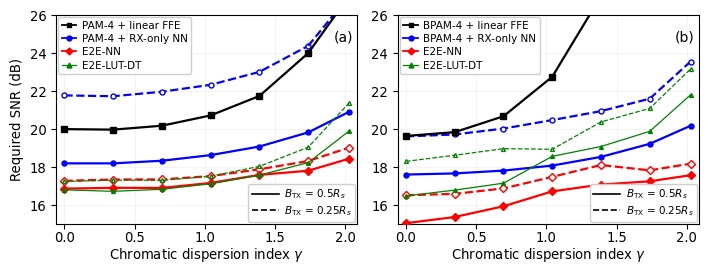

In [5]:
BANDS = sorted(TX_BANDWIDTH_GHZ, reverse=True)
LINE = {b: ("-", "--", "-.", ":")[i % 4] for i, b in enumerate(BANDS)}   # line style per TX filter bandwidth
WIDTH = 1.6                                     # line width of every curve but the trees
FONT, LEGEND_FONT = 9.5, 7.5
FIGURE_HEIGHT = 2.65                            # inches; the width is 3.5 inches per panel

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": FONT, "pdf.fonttype": 42})
fig, axes = plt.subplots(1, len(REGIMES), figsize=(3.5 * len(REGIMES), FIGURE_HEIGHT), sharey=True, squeeze=False)
legend_style = dict(fontsize=LEGEND_FONT, framealpha=.95, labelspacing=.3, borderpad=.35, handletextpad=.5,
                    borderaxespad=.2)
largest = gamma(max(FIBER_KM))
for ax, regime in zip(axes[0], REGIMES):
    for band in BANDS:
        wide = band == BANDS[0]
        for method in FIGURE_METHODS:
            name, marker, colour = STYLE[method]
            points, leaves = [], None
            for km in sorted(FIBER_KM):
                v = snr[(regime, band, km, method)]
                if v is not None:
                    points.append((gamma(km), v))
                elif points and leaves is None:
                    leaves = gamma(km)          # first length where BER 1e-3 is not reached
            if not points:
                continue
            thin = method == "trees"
            style = dict(color=colour, ls=LINE[band], lw=.9 if thin else WIDTH,
                         zorder=(5 if thin else 3) - (0 if wide else 1))
            ax.plot(*zip(*points), marker=marker, markersize=2.8 if thin else 1.2 + 1.5 * WIDTH,
                    markerfacecolor=colour if wide else "white", **style)
            if leaves is not None:              # out of the plot through the top
                ax.plot([points[-1][0], leaves], [points[-1][1], REQUIRED_SNR_DB[1] + 1], **style)
    ax.set_xlim(-.06, largest + .06)
    ax.set_xticks([t / 2 for t in range(int(2 * largest) + 1)])
    ax.set_ylim(*REQUIRED_SNR_DB)
    ax.set_xlabel(r"Chromatic dispersion index $\gamma$")
    ax.text(.985, .93, f"({'ab'[['electrical', 'optical'].index(regime)]})", transform=ax.transAxes,
            ha="right", va="top", fontsize=10)
    ax.tick_params(axis="x", pad=1.5)           # tick labels and axis label close to the axis
    ax.xaxis.labelpad = 1.
    ax.tick_params(labelleft=True)
    ax.grid(alpha=.25, lw=.4)
    fmt = FORMAT_NAME[FORMAT[regime]]
    names = {"linear": f"{fmt} + linear FFE", "rx_only": f"{fmt} + RX-only NN",
             "e2e": STYLE["e2e"][0], "trees": STYLE["trees"][0]}
    methods = ax.legend(handles=[Line2D([], [], color=STYLE[m][2], lw=.9 if m == "trees" else 1.3, marker=STYLE[m][1],
                                        markersize=3.5, label=names[m]) for m in FIGURE_METHODS],
                        loc="upper left", handlelength=1.4, **legend_style)
    ax.add_artist(methods)
    ax.legend(handles=[Line2D([], [], color="black", lw=1.2, ls=LINE[b],
                              label=rf"$B_{{\mathrm{{TX}}}}$ = {b / RS_GHZ:g}$R_s$") for b in BANDS],
              loc="lower right", handlelength=2.6, **legend_style)
axes[0, 0].set_ylabel("Required SNR (dB)")
fig.tight_layout(pad=.4, w_pad=1.0)
fig.savefig(WORK / "dispersion_figure.pdf")
fig.savefig(WORK / "dispersion_figure.png", dpi=220)
plt.show()

## 6. Column files

One file per noise regime: chromatic dispersion index, fiber length, then the required SNR of every
method and TX filter bandwidth (nan: BER 1e-3 not reached).

In [6]:
for regime in REGIMES:
    names = [f"{m}_bw{b:g}" for b in TX_BANDWIDTH_GHZ for m in FIGURE_METHODS]
    table = [[gamma(km), km] + [np.nan if snr[(regime, b, km, m)] is None else snr[(regime, b, km, m)]
                                for b in TX_BANDWIDTH_GHZ for m in FIGURE_METHODS] for km in FIBER_KM]
    path = WORK / f"dispersion_{regime}_{FORMAT[regime]}.txt"
    np.savetxt(path, np.array(table), fmt="%.4f", header="gamma km " + " ".join(names)
               + "\nrequired SNR (Es/N0, dB) at BER 1e-3 on the reference simulator; nan: not reached")
    print("written", path)

written c:\Users\celli\Documents\MLforCPO2\results\ofc_e2e\dispersion_electrical_pam4.txt
written c:\Users\celli\Documents\MLforCPO2\results\ofc_e2e\dispersion_optical_bpam.txt
